# Лекция 9. PPO: учимся на одном куске несколько раз

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/IlyaChichkanov/Reinforcement-learning/blob/main/09-ppo/lecture/lecture.ipynb)

**Главный вопрос сегодня: можно ли учиться на одном куске несколько раз — и не сломать стратегию?**

На прошлой лекции актор-критик сыграл кусок из $n$ шагов, сделал по нему **один** шаг градиента и больше к нему не возвращался. DQN в это же время доставал каждый переход из буфера десятки раз — и потому тратил меньше шагов в среде. Сегодня попробуем использовать кусок несколько раз: посмотрим, что при этом ломается и что с этим делает **PPO** (Proximal Policy Optimization) — метод, которым учат роботов и языковые модели.

Разделы:

1. Что ломается, если пройти по куску несколько раз
2. В loss ставим $\rho$ вместо $\log \pi$
3. PPO: несколько проходов по одному куску
4. Три варианта на лунном модуле
5. Тяга вместо кнопок
6. Итоги

In [1]:
# Ноутбук считается меньше минуты: по умолчанию берутся сохранённые результаты обучения.
TRAIN_LANDER = False      # True — обучить модуль заново: около 3 минут на запуск, в лекции 40 запусков
SEEDS = range(10)          # номера запусков
STEPS = 1_000_000         # шагов в среде на один запуск

import importlib.util, pathlib, subprocess, sys, urllib.error, urllib.request
if importlib.util.find_spec("Box2D") is None:                      # лунный модуль считает физический движок Box2D
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gymnasium[box2d]"], check=True)

# Служебные модули: в репозитории лежат рядом, в Google Colab скачиваются заново при каждом запуске.
RAW = "https://raw.githubusercontent.com/IlyaChichkanov/Reinforcement-learning/"
FILES = ("08-actor-critic/lecture/ac_core.py", "09-ppo/lecture/ppo_core.py", "09-ppo/lecture/ppo_plots.py",
         "09-ppo/lecture/lander_ppo_results.npz")
for file in FILES:
    local = pathlib.Path("../..") / file
    if local.exists():
        sys.path.append(str(local.parent)); continue
    for branch in ("main", "claude/reinforcement-learning-intro-u4zlwz"):    # пока лекция не влита — из ветки
        try:
            urllib.request.urlretrieve(f"{RAW}{branch}/{file}", pathlib.Path(file).name); break
        except urllib.error.HTTPError:
            continue

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from ppo_core import *            # среда и функции лекции 8 + сбор куска с log π старой стратегии
from ppo_plots import *           # картинки этой лекции
torch.set_num_threads(1)

## 1. Что ломается, если пройти по куску несколько раз

**Главная идея: веса действий посчитаны для той стратегии, которая сыграла кусок; с каждым проходом стратегия уходит от неё всё дальше, а веса остаются прежними.**

Напомним шаг актора-критика из лекции 8: сыграли кусок, для каждого шага посчитали вес действия — преимущество $A_t = G_t - V_w(s_t)$ — и сделали **один** шаг градиента по всему куску. Такой шаг будем называть **проходом**. После одного прохода кусок выбрасывается, хотя на него ушло больше сотни шагов в среде.

Соблазн очевидный: сделать по тому же куску ещё несколько проходов. Но вес $A_t$ посчитан для стратегии, которая кусок сыграла: и $G_t$ (что вышло после действия), и $V_w(s_t)$ (что обычно выходит из этого состояния) получены, когда дальше играла **она**. После первого прохода стратегия уже другая и после того же действия сыграла бы иначе — а веса в куске остались старые.

**Как измерить, насколько стратегия изменилась.** Для каждого шага куска делим вероятность сыгранного действия у новой стратегии на вероятность у старой — той, что кусок сыграла:

$$\rho_t \;=\; \frac{\pi_\theta(a_t \mid s_t)}{\pi_{\text{старая}}(a_t \mid s_t)}$$

$\rho_t = 1$ — вероятность не изменилась; $\rho_t = 1.4$ — действие стало в 1.4 раза вероятнее; $\rho_t = 0.5$ — вдвое реже. Будем считать, сколько шагов куска вышло за **коридор** от 0.8 до 1.2; почему границы такие — в разделе 3.

**Вопрос 1.** Берём стратегию, обученную актором-критиком на прошлой лекции, и играем ею один эпизод — он занял 225 шагов; это и есть наш кусок. Делаем по нему не один проход, а 10: те же данные, те же веса действий. Что станет с вероятностями сыгранных действий?

- **A.** Почти ничего: шаг градиента маленький, 10 проходов тоже мало что изменят.
- **B.** У части действий вероятность изменится в разы.
- **C.** Все вероятности вырастут: мы же 10 раз поощряли эти действия.

один проход  шагов в куске 225, ρ от 0.97 до 1.11, за коридор [0.8, 1.2] вышли 0 % шагов
10 проходов  шагов в куске 225, ρ от 0.60 до 2.60, за коридор [0.8, 1.2] вышли 28 % шагов


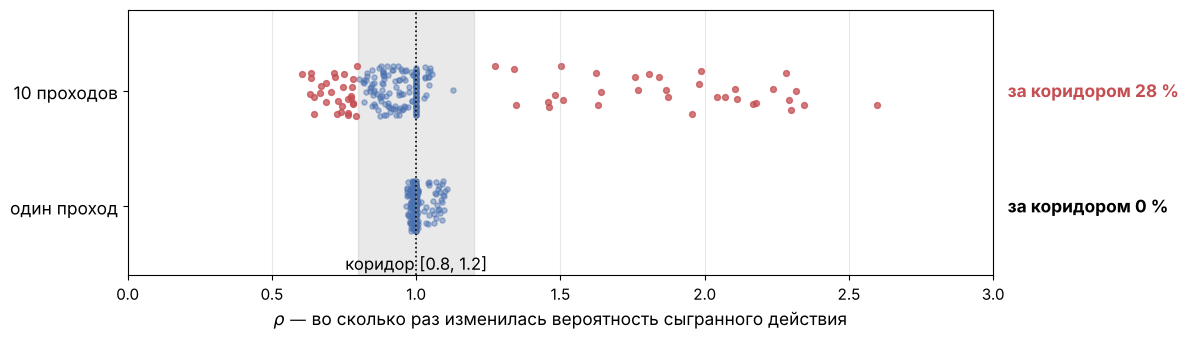

In [3]:
# кусок — один эпизод стратегии прошлой лекции; ρ считаем для каждого его шага
rho = {"один проход": measure_rho(epochs=1), "10 проходов": measure_rho(epochs=10)}
for name, values in rho.items():
    print(f"{name:12s} шагов в куске {len(values)}, ρ от {values.min():.2f} до {values.max():.2f},"
          f" за коридор [0.8, 1.2] вышли {100 * np.mean((values < 0.8) | (values > 1.2)):.0f} % шагов")
plot_rho(rho)
plt.show()

Ответ **B**. После одного прохода вероятности почти не меняются: $\rho$ от 0.97 до 1.11, за коридор не вышел ни один шаг. После десяти проходов $\rho$ доходит до 2.6 и падает до 0.60: за коридором 28 % шагов.

Вариант **C** неверен: поощряем мы только действия с положительным весом. У действий с отрицательным весом вероятность падает — на картинке это точки левее 1.

**Почему это плохо.** Вес $A_t$ говорит, насколько действие было лучше обычного **для той стратегии**, которая сыграла кусок. Новая стратегия выбирает в этих состояниях уже другое: старые веса её не описывают, а мы продолжаем по ним шагать.

**Одной строкой:** проходы по одному куску дают больше обучения из тех же данных, но уводят стратегию от той, для которой считались веса.

## 2. В loss ставим $\rho$ вместо $\log \pi$

**Главная идея: в loss вместо $\log \pi$ ставят $\rho_t$ — смысл слагаемого тот же, но теперь в формуле видно, насколько стратегия ушла от старой.**

В лекции 8 та часть loss, что учит актора, была суммой по шагам куска: слагаемое шага $t$ — это вес $A_t$, умноженный на $\log \pi_\theta(a_t \mid s_t)$. Теперь слагаемое шага другое:

$$\rho_t \, A_t \qquad \text{вместо} \qquad A_t \log \pi_\theta(a_t \mid s_t)$$

Сумму таких слагаемых мы **увеличиваем** (в коде, как и раньше, перед ней стоит минус: оптимизатор умеет только уменьшать). Что для этого выгодно:

- у шага с $A_t > 0$ — поднять $\rho_t$, то есть сделать действие вероятнее, чем оно было у старой стратегии;
- у шага с $A_t < 0$ — опустить $\rho_t$, сделать действие реже.

На первом проходе новая стратегия ещё совпадает со старой, $\rho_t = 1$, и слагаемое $\rho_t A_t$ двигает сеть точно так же, как $A_t \log \pi_\theta$ в лекции 8. Чтобы считать $\rho_t$, при сборе куска запоминаем $\log \pi_{\text{старая}}(a_t \mid s_t)$ — в коде это `logp_old`.

**Вопрос 2.** В каком-то состоянии куска старая стратегия давала сыгранному действию вероятность 0.10, а новая даёт 0.14. Чему равно $\rho_t$ и что это значит?

- **A.** $\rho_t = 0.04$ — вероятность выросла на 4 процентных пункта.
- **B.** $\rho_t = 1.4$ — действие стало в 1.4 раза вероятнее, чем было.
- **C.** $\rho_t = 1.4$ — действие стало в 1.4 раза лучше.

Ответ **B**: $\rho_t = 0.14 / 0.10 = 1.4$ — вероятность сыгранного действия выросла в 1.4 раза. Про то, хорошее действие или плохое, $\rho_t$ не говорит ничего: это дело веса $A_t$.

**Откуда эта запись.** Так же записывал loss TRPO (2015), предшественник PPO. Он на каждом шаге решал задачу с ограничением «новая стратегия должна быть близка к старой» — строго, но тяжело считать. PPO (2017) заменил ограничение одной строкой; её и разберём.

**Одной строкой:** слагаемое шага теперь $\rho_t A_t$: при $\rho_t = 1$ это шаг лекции 8, а дальше $\rho_t$ показывает, насколько стратегия ушла от той, что собрала кусок.

## 3. PPO: несколько проходов по одному куску

**Главная идея: когда $\rho_t$ уходит за коридор в выгодную для шага сторону, его слагаемое обрезают — и этот шаг куска перестаёт двигать сеть дальше.**

$$\text{слагаемое шага в PPO} \;=\; \min\Big(\rho_t A_t,\ \ \mathrm{clip}(\rho_t,\ 1-\varepsilon,\ 1+\varepsilon)\, A_t\Big), \qquad \varepsilon = 0.2$$

Разберём по частям.

1. $\mathrm{clip}(\rho_t,\ 1-\varepsilon,\ 1+\varepsilon)$ зажимает $\rho_t$ в коридор: что меньше 0.8, становится 0.8, что больше 1.2 — становится 1.2. При $\varepsilon = 0.2$ это тот самый коридор $[0.8,\ 1.2]$ из раздела 1.
2. Получаются два числа: необрезанное $\rho_t A_t$ и обрезанное $\mathrm{clip}(\rho_t)\, A_t$. Внутри коридора они совпадают.
3. Из двух берётся **меньшее**. Что из этого выходит, видно на картинке ниже: синяя линия — слагаемое шага, серая штриховая — оно же без обрезки.

**Вопрос 3.** Действие оказалось лучше обычного ($A_t > 0$), и после нескольких проходов $\rho_t$ дошёл до 1.5 — за коридор $[0.8,\ 1.2]$. Что добавит слагаемое этого шага к градиенту?

- **A.** Будет и дальше поднимать вероятность этого действия: оно же хорошее.
- **B.** Ничего: обрезанное слагаемое от $\rho_t$ уже не зависит.
- **C.** Потянет вероятность обратно в коридор.

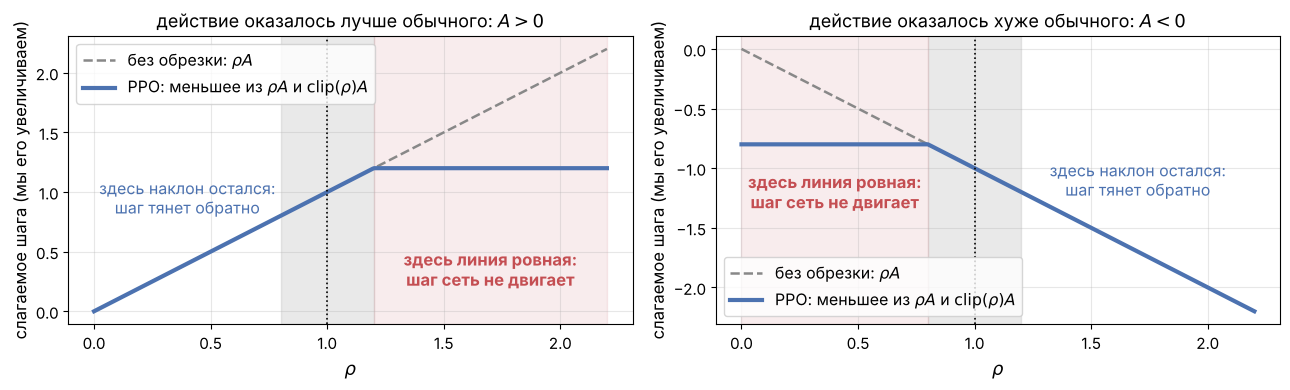

In [4]:
draw_clip(eps=0.2)
plt.show()

Ответ **B**. При $A_t > 0$ и $\rho_t > 1.2$ меньшее из двух чисел — обрезанное, $1.2\,A_t$. От $\rho_t$ оно не зависит: на левой картинке синяя линия идёт ровно. Производная равна нулю — этот шаг куска больше ничего не добавляет к градиенту. Обратно в коридор клиппинг не тянет (вариант **C**): он не наказывает за уход, а перестаёт за него платить.

**Зачем минимум.** Он оставляет обрезку только с той стороны, куда шагу выгодно уходить: при $A_t > 0$ — справа от коридора, при $A_t < 0$ — слева (правая картинка: вероятность плохого действия нельзя давить вниз без конца). С другой стороны линия остаётся наклонной: если вероятность ушла в невыгодную сторону, шаг по-прежнему тянет её назад.

**Важная оговорка.** Всё это — про **один** шаг куска. Сеть у всех шагов общая, поэтому вероятность его действия всё равно может сдвинуться из-за остальных шагов. Гарантии «стратегия останется в коридоре» клиппинг не даёт: в опыте ниже наибольший $\rho$ с клиппингом — 1.22, чуть выше границы 1.2.

Проверим, как клиппинг работает на том же куске, что в разделе 1:

один проход                    ρ от 0.97 до 1.11, за коридор [0.8, 1.2] вышли 0 % шагов
10 проходов                    ρ от 0.60 до 2.60, за коридор [0.8, 1.2] вышли 28 % шагов
PPO: 10 проходов с клиппингом  ρ от 0.89 до 1.22, за коридор [0.8, 1.2] вышли 1 % шагов


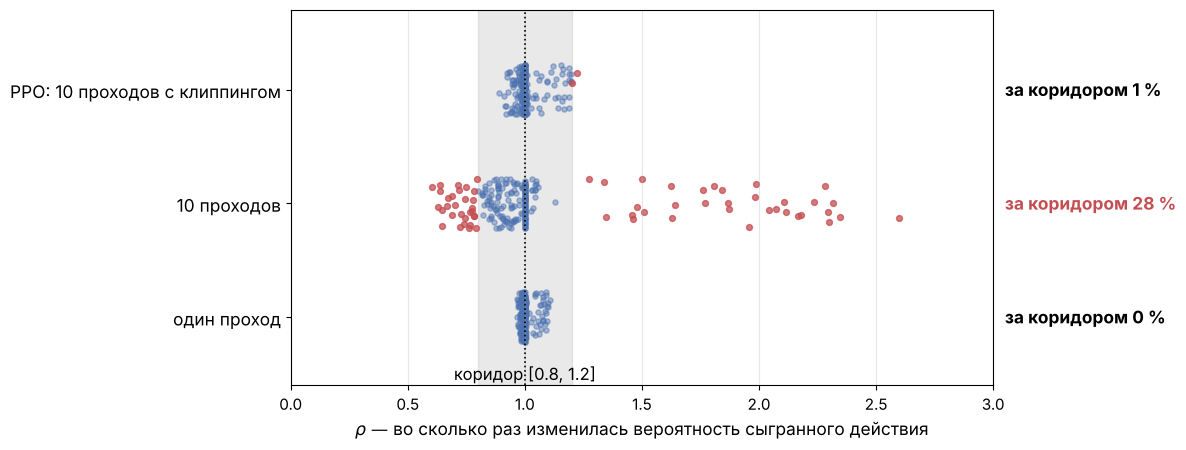

In [5]:
rho["PPO: 10 проходов с клиппингом"] = measure_rho(epochs=10, clip=True)
for name, values in rho.items():
    print(f"{name:30s} ρ от {values.min():.2f} до {values.max():.2f},"
          f" за коридор [0.8, 1.2] вышли {100 * np.mean((values < 0.8) | (values > 1.2)):.0f} % шагов")
plot_rho(rho)
plt.show()

С клиппингом те же 10 проходов уводят стратегию заметно меньше: за коридором — 1 % шагов против 28 % без него, а наибольший $\rho$ — 1.22 вместо 2.6. Это измерение, а не гарантия: отдельные шаги за коридор всё же выходят.

Весь PPO — это три изменения в коде актора-критика: запомнить $\log \pi$ при сборе куска, считать $\rho_t$ и обрезать слагаемые, сделать по куску несколько проходов. Они помечены `# ← новое`.

**Про размер куска.** `collect` играет до $n = 2048$ шагов, но останавливается, когда эпизод кончился. Эпизод модуля не длиннее 1000 шагов, поэтому кусок здесь — всегда один эпизод; в опыте выше он занял 225 шагов.

In [6]:
def train(seed, steps=STEPS, n=2048, epochs=10, eps=0.2, clip=True):
    # кусок играется один раз, потом по нему делается epochs проходов; clip=False — то же, но без обрезки
    rng, env = np.random.default_rng(seed), make_lander()
    actor, critic = make_net(4, seed), make_net(1, seed + 1000)
    opt = torch.optim.Adam([{"params": actor.parameters(), "lr": 0.0003},
                            {"params": critic.parameters(), "lr": 0.001}])
    played, total, history = 0, 0.0, []
    s, _ = env.reset(seed=seed * 10_000)
    while played < steps:
        # ← новое: collect запоминает ещё и log π сыгранных действий — logp_old
        states, actions, rewards, logp_old, s, terminated, truncated = collect(actor, env, s, rng, n)
        tail = 0.0 if terminated else critic(torch.as_tensor(s)).item()
        G = torch.as_tensor(returns_to_go(rewards, tail=tail), dtype=torch.float32)
        states, actions, logp_old = torch.as_tensor(states), torch.as_tensor(actions), torch.as_tensor(logp_old)
        advantage = (G - critic(states).squeeze(1)).detach()                    # вес действия A_t, как в лекции 8
        for _ in range(epochs):                                                 # ← новое: несколько проходов по куску
            ratio = torch.exp(log_probs_of(actor, states, actions) - logp_old)  # ← новое: ρ_t = π_новая / π_старая
            terms = ratio * advantage                                           # слагаемые шагов: ρ_t · A_t
            if clip:                                                            # ← новое: меньшее из двух чисел
                terms = torch.min(terms, ratio.clamp(1 - eps, 1 + eps) * advantage)
            loss_actor = -terms.mean()                                          # среднее: шаг не зависит от длины куска
            loss_critic = ((G - critic(states).squeeze(1)) ** 2).mean()
            loss = loss_actor + loss_critic
            opt.zero_grad(); loss.backward(); opt.step()
        played += len(rewards); total += rewards.sum()
        if terminated or truncated:
            history.append((played, total)); total = 0.0
            s, _ = env.reset(seed=seed * 10_000 + len(history))
    return np.array(history), actor, critic

**Одной строкой:** PPO обрезает слагаемое шага, когда $\rho_t$ уходит за коридор в выгодную сторону, — и этот шаг перестаёт двигать сеть; на нашем куске после 10 проходов за коридором — 1 % шагов вместо 28 %.

## 4. Три варианта на лунном модуле

**Главная идея: проверяем на модуле, что дают повторные проходы и что добавляет клиппинг, — меняя в одной функции ровно две настройки.**

| вариант | `epochs` | `clip` |
|---|---|---|
| один проход (как в лекции 8) | 1 | нет |
| 10 проходов, без клиппинга | 10 | нет |
| PPO: 10 проходов с клиппингом | 10 | да |

**Вопрос 4.** Какой из трёх вариантов за миллион шагов в среде подойдёт ближе всего к посадке (к 200)?

- **A.** Один проход: веса честные, стратегия не уезжает.
- **B.** 10 проходов без клиппинга: обучения из тех же данных больше всего.
- **C.** 10 проходов с клиппингом.

один проход
    среднее последних 100 эпизодов: -31; по запускам: -48 -46 -44 -41 -33 -28 -25 -24 -19 -2; не меньше 200 — в 0 из 10
    до среднего 200 дошли 0 из 10 запусков


10 проходов, без клиппинга
    среднее последних 100 эпизодов: 26; по запускам: -52 -22 -19 -13 4 24 28 56 91 167; не меньше 200 — в 0 из 10
    до среднего 200 дошли 0 из 10 запусков
PPO: 10 проходов с клиппингом
    среднее последних 100 эпизодов: 173; по запускам: 136 136 139 146 163 186 193 202 209 220; не меньше 200 — в 3 из 10
    до среднего 200 дошли 5 из 10 запусков, шагов в среде, тыс.: 226 237 460 530 714


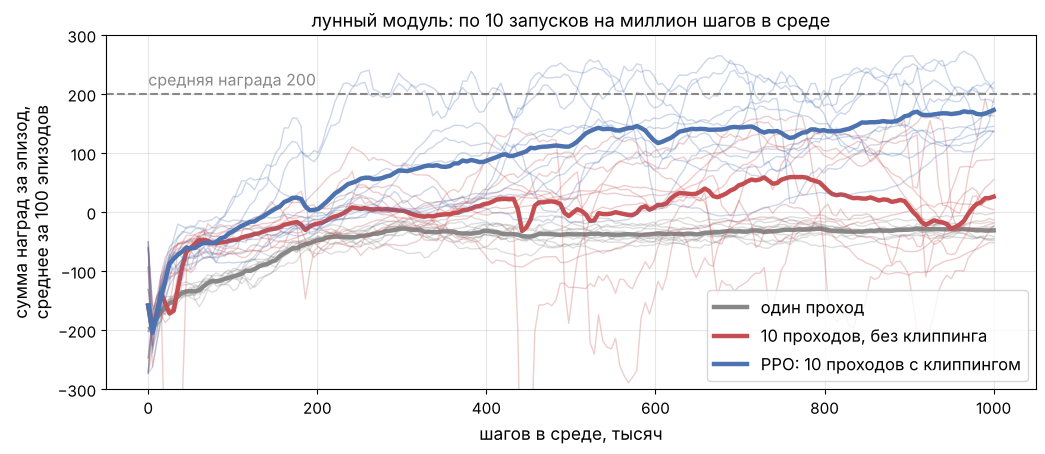

In [7]:
runs = {}
for name, kind, settings in (("один проход", "plain1", dict(epochs=1, clip=False)),
                             ("10 проходов, без клиппинга", "plain10", dict(epochs=10, clip=False)),
                             ("PPO: 10 проходов с клиппингом", "ppo", dict(epochs=10, clip=True))):
    runs[name] = [train(seed, **settings)[0] for seed in SEEDS] if TRAIN_LANDER else load_runs(kind)
    print_runs(name, runs[name])
plot_lander_steps(runs, title="лунный модуль: по 10 запусков на миллион шагов в среде")
plt.show()

Ответ **C**. Среднее последних 100 эпизодов: −31 у одного прохода, 26 у десяти проходов без клиппинга и 173 у PPO.

**Почему так выходит.** Один проход — это один шаг градиента на эпизод: из каждого эпизода сеть берёт мало. Десять проходов — десять шагов на тех же данных, и уже это помогло (26 против −31). Но без клиппинга часть этих шагов делается по весам, которые нынешнюю стратегию уже не описывают, и запуски расходятся (от −52 до 167). Наибольший прирост дал клиппинг: 173.

**Как читать вывод.** В нём две разные мерки. Первая строка — чем обучение **закончилось**: среднее последних 100 эпизодов; не меньше 200 оно у 3 запусков PPO из 10. Вторая — в скольких запусках скользящее среднее **хотя бы раз** дошло до 200: таких 5 (за 226–714 тысяч шагов). Выйти на посадку легче, чем удержаться.

Прямо сравнивать эти числа с актором-критиком прошлой лекции нельзя: там были другие настройки (кусок 128 шагов, шаг обучения 0.0007). Заметить стоит одно: у PPO запуски держатся кучнее — 136–220 против 61–215 в лекции 8.

**Одной строкой:** на этих настройках повторные проходы помогли сами по себе, а наибольший прирост дал клиппинг.

## 5. Тяга вместо кнопок

**Главная идея: чтобы перейти к действиям-числам, в PPO меняется только то, как стратегия выбирает действие и как считается его $\log \pi$.**

До сих пор модуль управлялся четырьмя кнопками. У того же модуля есть вариант, где действие — **два числа** от −1 до 1: насколько открыт главный двигатель и насколько боковой. Вероятность каждому числу не припишешь — чисел бесконечно много. Поэтому стратегия устроена иначе:

1. Сеть выдаёт два **средних** $\mu_\theta(s)$ — какую тягу она считает лучшей.
2. К каждому среднему прибавляется случайная добавка с **разбросом** $\sigma$: получается действие $u$ — два числа из нормального распределения. Разброс — ещё два параметра, они учатся вместе с сетью.
3. Среде передаётся $\mathrm{clip}(u,\ -1,\ 1)$: открыть двигатель сильнее, чем на полную, нельзя.
4. Вместо вероятности кнопки берётся **плотность** нормального распределения в точке $u$ (до обрезки): чем ближе $u$ к среднему, тем она больше. Её логарифм и есть $\log \pi$.

Всё остальное — преимущества, $\rho$, клиппинг, несколько проходов — не меняется. В коде помечены пять новых мест.

In [8]:
def train_continuous(seed, steps=STEPS, n=2048, epochs=10, eps=0.2, sigma=0.5):
    # тот же PPO на непрерывном модуле: действие — два числа от −1 до 1
    rng, env = np.random.default_rng(seed), make_lander(continuous=True)              # ← новое: среда
    actor, critic = make_net(2, seed), make_net(1, seed + 1000)                       # ← новое: на выходе два средних
    log_sigma = torch.full((2,), float(np.log(sigma)), requires_grad=True)            # ← новое: разброс — тоже параметры
    opt = torch.optim.Adam([{"params": actor.parameters(), "lr": 0.0003},
                            {"params": [log_sigma], "lr": 0.0003},
                            {"params": critic.parameters(), "lr": 0.001}])
    played, total, history = 0, 0.0, []
    s, _ = env.reset(seed=seed * 10_000)
    while played < steps:
        # ← новое: действие берётся из нормального распределения
        states, actions, rewards, logp_old, s, terminated, truncated = collect_continuous(actor, log_sigma, env, s, rng, n)
        tail = 0.0 if terminated else critic(torch.as_tensor(s)).item()
        G = torch.as_tensor(returns_to_go(rewards, tail=tail), dtype=torch.float32)
        states, actions, logp_old = torch.as_tensor(states), torch.as_tensor(actions), torch.as_tensor(logp_old)
        advantage = (G - critic(states).squeeze(1)).detach()
        for _ in range(epochs):
            log_pi = log_prob_normal(actor(states), log_sigma, actions)               # ← новое: log π — логарифм плотности
            ratio = torch.exp(log_pi - logp_old)
            terms = torch.min(ratio * advantage, ratio.clamp(1 - eps, 1 + eps) * advantage)
            loss_actor = -terms.mean()
            loss_critic = ((G - critic(states).squeeze(1)) ** 2).mean()
            loss = loss_actor + loss_critic
            opt.zero_grad(); loss.backward(); opt.step()
        played += len(rewards); total += rewards.sum()
        if terminated or truncated:
            history.append((played, total)); total = 0.0
            s, _ = env.reset(seed=seed * 10_000 + len(history))
    return np.array(history), actor, critic, log_sigma.detach()

PPO, непрерывные действия
    среднее последних 100 эпизодов: 113; по запускам: -20 105 106 114 114 133 139 139 146 152; не меньше 200 — в 0 из 10
    до среднего 200 дошли 1 из 10 запусков, шагов в среде, тыс.: 660


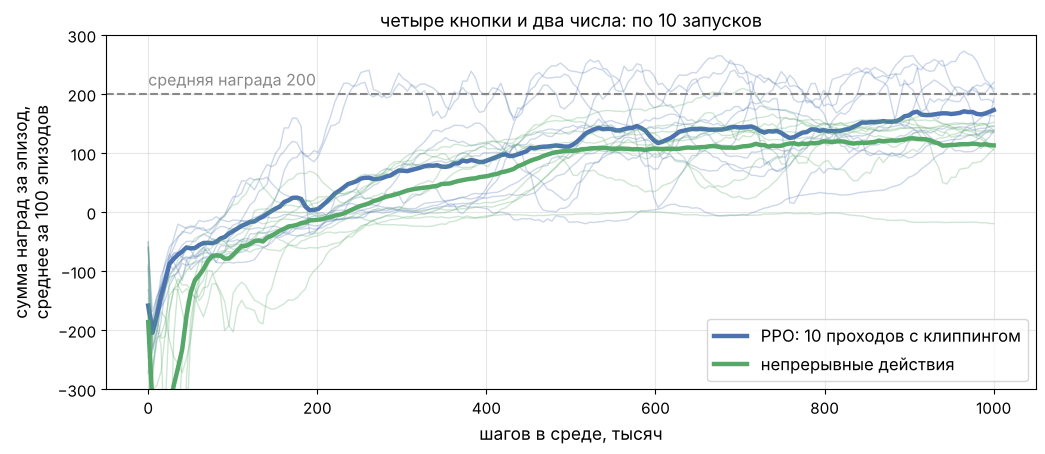

In [9]:
cont = [train_continuous(seed)[0] for seed in SEEDS] if TRAIN_LANDER else load_runs("cont")
print_runs("PPO, непрерывные действия", cont)
plot_lander_steps({"PPO: 10 проходов с клиппингом": runs["PPO: 10 проходов с клиппингом"],
                   "непрерывные действия": cont}, title="четыре кнопки и два числа: по 10 запусков")
plt.show()

За тот же миллион шагов непрерывный модуль выходит в среднем на 113 против 173 у четырёх кнопок и садится реже: скользящего среднего 200 достиг 1 запуск из 10. Это ожидаемо: выбрать одну кнопку из четырёх проще, чем подобрать две тяги. Код при этом изменился в пяти местах: среда, выход сети, разброс $\sigma$, выбор действия и $\log \pi$.

Так выглядит посадка непрерывного модуля стратегией PPO:

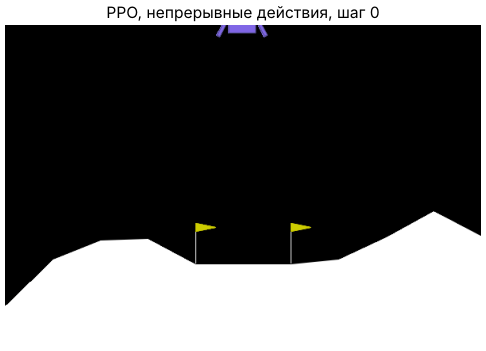

## 6. Итоги

1. **Проблема.** Вес действия посчитан для стратегии, сыгравшей кусок. После одного прохода стратегия почти та же, после десяти — у 28 % шагов $\rho$ выходит за коридор $[0.8,\ 1.2]$, и старые веса её уже не описывают.
2. **Мерка.** $\rho_t = \pi_\theta(a_t \mid s_t) / \pi_{\text{старая}}(a_t \mid s_t)$ — во сколько раз изменилась вероятность сыгранного действия. В loss слагаемое шага — $\rho_t A_t$.
3. **Клиппинг.** Слагаемое шага $\min(\rho_t A_t,\ \mathrm{clip}(\rho_t)A_t)$: когда $\rho_t$ уходит за коридор $[0.8,\ 1.2]$ в выгодную сторону, оно перестаёт расти, и этот шаг перестаёт двигать сеть. Удержать стратегию в коридоре это не гарантирует, но на нашем куске за коридором — 1 % шагов вместо 28 %.
4. **PPO в четырёх шагах:** сыграть кусок и запомнить $\log \pi$ → посчитать преимущества → сделать по куску несколько проходов с обрезанными слагаемыми → идти играть следующий кусок.
5. **Непрерывные действия.** Сеть выдаёт средние, действие берётся из нормального распределения, а $\log \pi$ считается по плотности. На модуле с двумя тягами PPO выходит на 113 за миллион шагов.

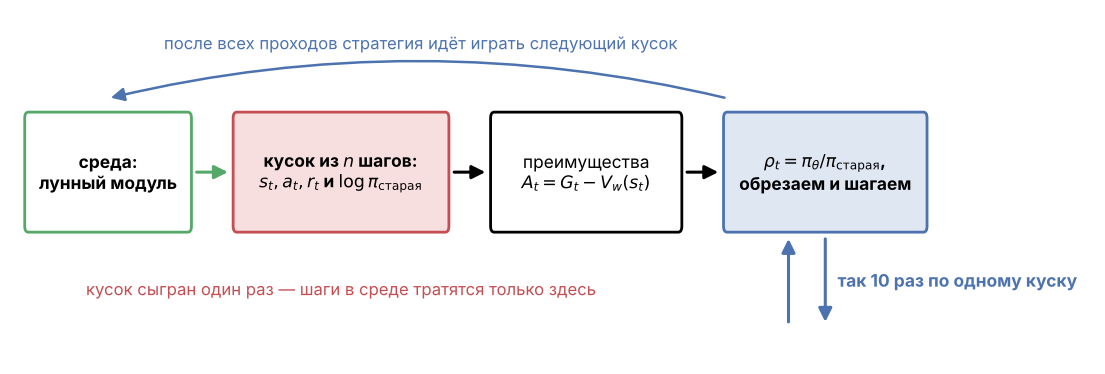

In [10]:
draw_ppo_scheme()
plt.show()

> **Простыми словами — вся лекция.** Данные собраны одной стратегией, а учим мы уже другую. Пока новая близка к старой, данные ещё годятся. PPO на каждом шаге куска следит, во сколько раз изменилась вероятность сыгранного действия, и перестаёт подталкивать её дальше, когда она ушла за коридор. Поэтому по одному куску делают несколько проходов.

**Где это работает.** PPO — один из самых ходовых методов RL: на нём учат ходить роботов и играть ботов в Dota 2. На нём же устроено дообучение языковых моделей по оценкам людей (RLHF): вместо среды — диалог, вместо наград — оценка ответа, а чтобы модель не «уехала» от исходной, ставят похожее ограничение на отличие стратегий. GRPO, которым учат рассуждающие модели, — упрощение PPO: критика заменяет среднее по нескольким ответам на один вопрос.

Словарь лекции: **проход, отношение вероятностей $\rho$ (importance ratio), клиппинг (clipping), PPO, TRPO, гауссова стратегия**.

## Литература

* Schulman J. и др. *Proximal policy optimization algorithms*, 2017 — PPO. [arxiv.org/abs/1707.06347](https://arxiv.org/abs/1707.06347)
* Schulman J. и др. *Trust region policy optimization*. ICML, 2015 — TRPO, предшественник.
* Саттон Р., Барто Э. *Обучение с подкреплением*, 2-е изд., раздел 13.5 — актор-критик.
* [Учебник по машинному обучению ШАД, глава «Обучение с подкреплением»](https://education.yandex.ru/handbook/ml/article/obuchenie-s-podkrepleniem).

## На семинаре и дома

* Домашнее задание по лекциям 8–9 объявит преподаватель.